# imports

In [59]:
import sys
import os
import json
import numpy as np
import scipy as sp
import pandas as pd

import importlib

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils

from utils import ai_slob

In [60]:
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)

importlib.reload(ai_slob)

<module 'utils.ai_slob' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/ai_slob.py'>

In [61]:
# specific

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils
sys.path.append(os.path.join(os.getcwd(), '../../../worm-control/src'))
from utils_worm_control import read_utils as read_utils_control

In [62]:
importlib.reload(read_utils)
importlib.reload(read_utils_control)

<module 'utils_worm_control.read_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/worm-2025-fieseler/notebooks/analysis/../../../worm-control/src/utils_worm_control/read_utils.py'>

# setup

In [63]:
ll = 'll00'
data_variant = 'gcamp'

save = False

In [64]:
# specific

model_variant = 'ns'
organism = 'worm'
manual = False
full = False

In [65]:
file_ids = list(range(0, 33+1))
# file_ids = [19, 20, 21]

# load

In [66]:
state_key, state_label = analysis_utils.get_plot_class(organism)
model_path = read_utils.get_model_path()

filenames = analysis_utils.read_filenames(organism, file_ids)
metadata = (filenames, model_path, model_variant, data_variant, manual, full)

# scores

In [67]:
((boms_spn, _, _, _, _, _, _),
 (hgms_spn, _, _, _, _, _, _)) = analysis_utils.read_predictionss(*metadata)


# list_of_significant_neurons = [analysis_utils.get_significant_neurons(filename, model_variant, mode='hgm') for filename in filenames]
#
# for file_id in range(len(list_of_significant_neurons)):
# 	labels = list(list_of_significant_neurons[file_id].columns)
# 	for split_id in range(len(boms_spn[file_id])):
# 		for column in boms_spn[file_id][split_id].columns:
# 			if column not in labels:
# 				boms_spn[file_id][split_id] = boms_spn[file_id][split_id].drop(column, axis=1)
# 	for split_id in range(len(hgms_spn[file_id])):
# 		for column in hgms_spn[file_id][split_id].columns:
# 			if column not in labels:
# 				hgms_spn[file_id][split_id] = hgms_spn[file_id][split_id].drop(column, axis=1)


neuron_scores = analysis_utils.assemble_scoress(boms_spn, hgms_spn)

In [41]:
# plot_utils.plot_performance_plot(
# 	neuron_scores, None,
# 	title='scores for all neurons', limits=None, force_medians=True, horizontal_bps=False,
# 	# save_path=f'../../out/plots/scores/gfp_control/{model_variant}_scores_all' if save else None,
# 	save_path=None
# )

In [42]:
# plot_utils.plot_performance_plot(
# 	{key: neuron_scores[key] for key in neuron_scores.keys() if not key[0].isdigit()}, None,
# 	title='scores for ID\'d neurons', limits=None, force_medians=False, horizontal_bps=False,
# 	# save_path=f'../../out/plots/scores/gfp_control/{model_variant}_scores_id' if save else None,
# 	save_path=None
# )

# GFP control

In [68]:
file_ids_gfp = range(0, 7+1)
# file_ids_gfp = [2, 3, 4]

filenames_gfp = analysis_utils.read_filenames(organism, file_ids_gfp, data_variant='gfp')
metadata_gfp = (filenames_gfp, model_path, model_variant, 'gfp', manual, full)

((boms_spn_gfp, _, _, _, _, _, _),
 (hgms_spn_gfp, _, _, _, _, _, _)) = analysis_utils.read_predictionss(*metadata_gfp)

neuron_scores_gfp = analysis_utils.assemble_scoress(boms_spn_gfp, hgms_spn_gfp)

In [44]:
# ai_slob.plot_performance_histogram(neuron_scores,
# 								   neuron_scores_gfp,
# 								   title='performance histogram for all neurons', threshold=0.95,
# 								   save_path=f'../../out/plots/scores/gfp_control/{model_variant}_scores_hist' if save else None
# 								   )

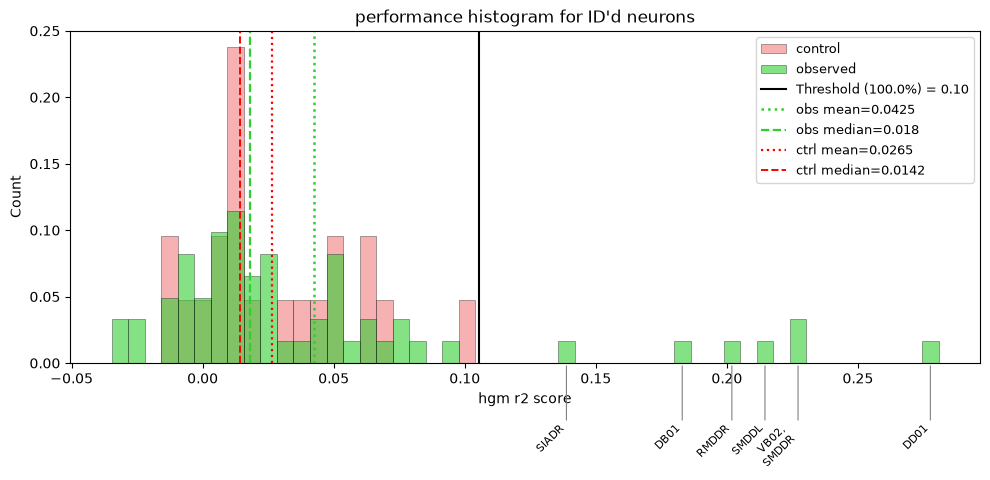

(<Figure size 1000x500 with 1 Axes>,
 <Axes: title={'center': "performance histogram for ID'd neurons"}, xlabel='hgm r2 score', ylabel='Count'>)

In [69]:
importlib.reload(ai_slob)
ai_slob.plot_performance_histogram(neuron_scores,
								   neuron_scores_gfp,
								   title='performance histogram for ID\'d neurons', threshold=1, figsize=(10, 5), id_only=True,
								   save_path=f'../../out/plots/scores/gfp_control/{model_variant}_scores_hist_id' if save else None
								   )

In [46]:
# plot_utils.plot_performance_plot(
# 	neuron_scores, neuron_scores_gfp,
# 	title='scores for all neurons (+ GFP)', limits=None, force_medians=False, threshold=0.95, control_cutoff=False, horizontal_bps=False,
# 	# save_path=f'../../out/plots/scores/gfp_control/{model_variant}_scores_all_gfp' if save else None,
# 	save_path=None,
# )

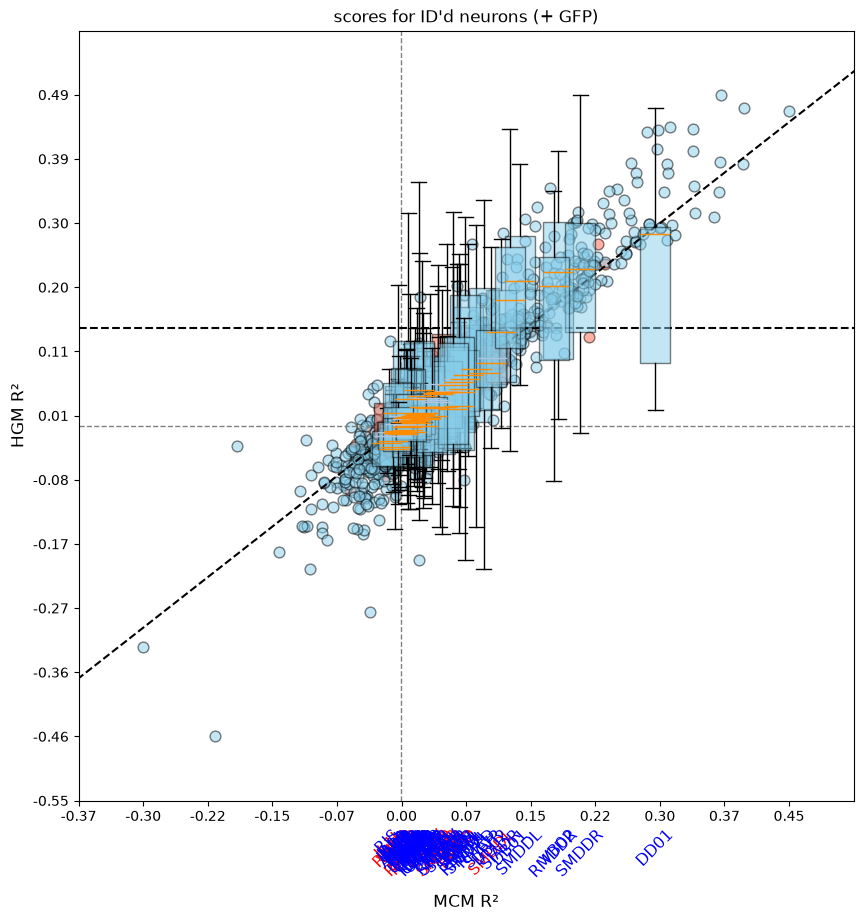

In [70]:
plot_utils.plot_performance_plot(
	{key: neuron_scores[key] for key in neuron_scores.keys() if not key[0].isdigit()},
	{key: neuron_scores_gfp[key] for key in neuron_scores_gfp.keys() if not key[0].isdigit()},
	title='scores for ID\'d neurons (+ GFP)', limits=None, force_medians=False, control_cutoff=False, horizontal_bps=False,
	# save_path=f'../../out/plots/scores/gfp_control/{model_variant}_scores_id_gfp' if save else None,
	save_path=None,
)

In [71]:
# threshold_hgm_gfp = np.quantile(np.concatenate([pair[1] for pair in neuron_scores_gfp.values()]), 0.95)
threshold_hgm_gfp = 0.1
# threshold_bom_gfp = np.quantile(np.concatenate([pair[0] for pair in neuron_scores_gfp.values()]), 0.95)
threshold_bom_gfp = np.array(0)

neuron_scores_hgm_sig = list(reversed(sorted({key: value for key, value in neuron_scores.items() if np.median(value[1].reshape(-1, 1)) > threshold_hgm_gfp}.items(), key=lambda x: np.median(x[1][1]))))
neuron_scores_hgm_sig_labels = list([val[0] for val in neuron_scores_hgm_sig])

print('\n'.join([f'NEURON: {key},\t\tHGMSCR: {np.median(val[1]):.4f}' for key, val in neuron_scores_hgm_sig if not key[0].isdigit()]))

NEURON: DD01,		HGMSCR: 0.2808
NEURON: SMDDR,		HGMSCR: 0.2302
NEURON: VB02,		HGMSCR: 0.2258
NEURON: SMDDL,		HGMSCR: 0.2120
NEURON: RMDDR,		HGMSCR: 0.2045
NEURON: DB01,		HGMSCR: 0.1844
NEURON: SIADR,		HGMSCR: 0.1366


In [72]:
# plot_utils.plot_performance_plot(
# 	{key: neuron_scores[key] for key in neuron_scores_hgm_sig_labels}, None,
# 	title='scores for significant neurons', limits=None, force_medians=True, horizontal_bps=False,
# 	# save_path=f'../../out/plots/scores/gfp_control/{model_variant}_scores_significant' if save else None,
# 	save_path=None
# )

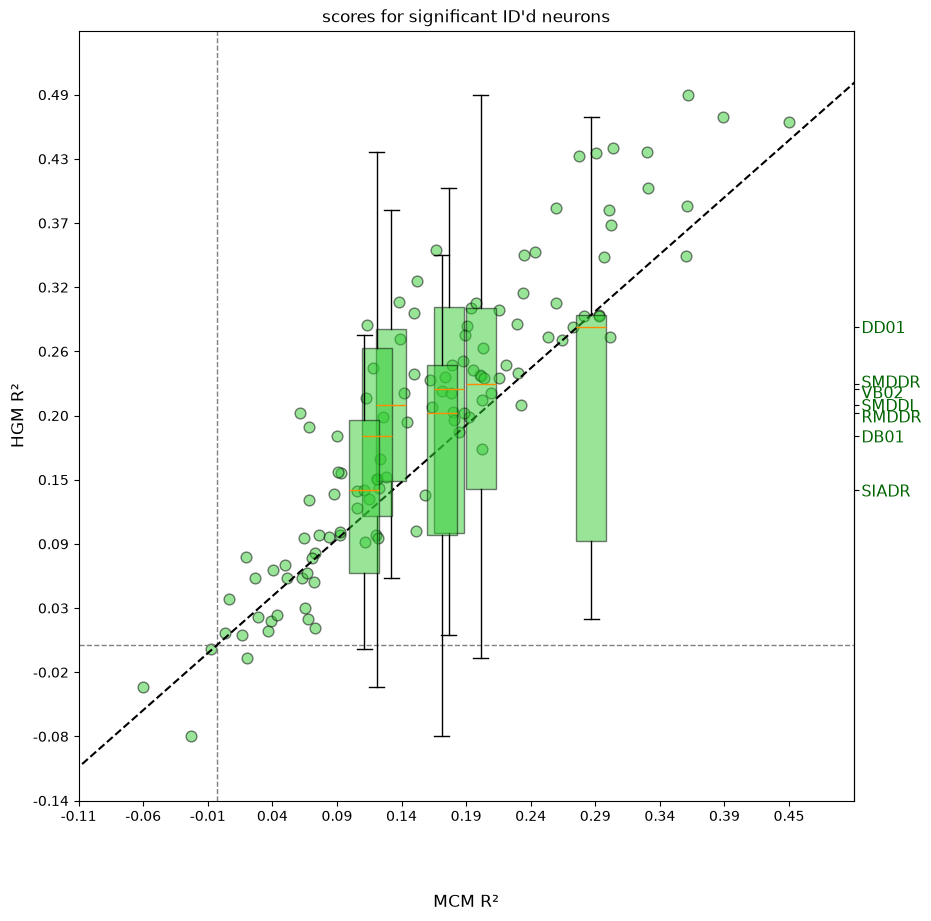

In [100]:
importlib.reload(plot_utils)
plot_utils.plot_performance_plot(
	{key: neuron_scores[key] for key in neuron_scores_hgm_sig_labels if not key[0].isdigit()}, None,
	title='scores for significant ID\'d neurons', limits=None, force_medians=False, horizontal_bps=False,
	save_path=f'../../out/plots/scores/gfp_control/{model_variant}_scores_id_significant' if save else None
)

In [51]:
# plot_utils.plot_improvement_plot(
# 	{key: neuron_scores[key] for key in neuron_scores_hgm_sig_labels},
# 	title='score improvements for significant neurons', limits=None, force_medians=True, horizontal_bps=False,
# 	# save_path=f'../../out/plots/scores/gfp_control/{model_variant}_impros_significant' if save else None,
# 	save_path=None
# )

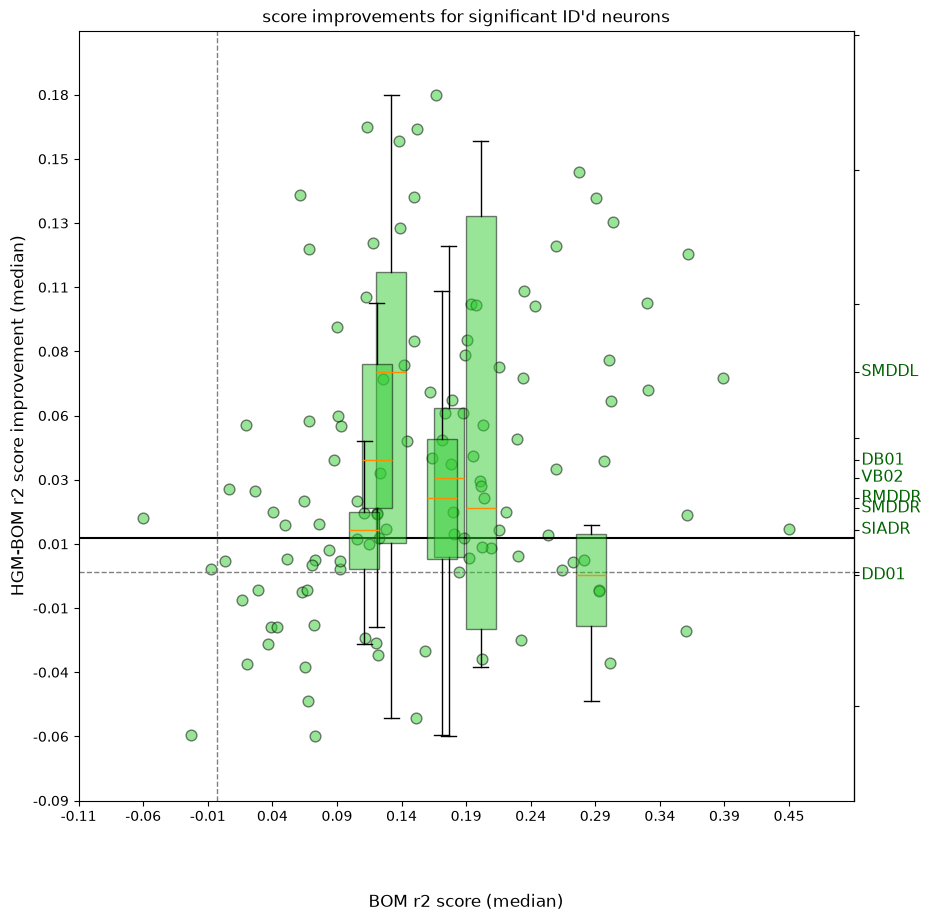

In [74]:
importlib.reload(plot_utils)
plot_utils.plot_improvement_plot(
	{key: neuron_scores[key] for key in neuron_scores_hgm_sig_labels if not key[0].isdigit()}, None,
	title='score improvements for significant ID\'d neurons', limits=None, force_medians=False, horizontal_bps=False,
	save_path=f'../../out/plots/scores/gfp_control/{model_variant}_impros_id_significant' if save else None
)

In [53]:
neuron_scores_hgm_sig_labels_id = [label for label in neuron_scores_hgm_sig_labels if not label[0].isdigit()]


improvement_medians = {}
for label in neuron_scores_hgm_sig_labels_id:
	if label in neuron_scores:
		bom_scores, hgm_scores = neuron_scores[label]
		improvements = np.array(hgm_scores) - np.array(bom_scores)
		median_improvement = np.median(improvements)
		improvement_medians[label] = median_improvement

improvement_gfp_medians = {}
for label in neuron_scores_gfp.keys():
	if not label[0].isdigit():
		bom_scores, hgm_scores = neuron_scores_gfp[label]
		improvements = np.array(hgm_scores) - np.array(bom_scores)
		median_improvement = np.median(improvements)
		improvement_gfp_medians[label] = median_improvement

percentile_100 = max(improvement_gfp_medians.values())
print(percentile_100)

for label in improvement_medians.keys():
	print(label, improvement_medians[label], improvement_medians[label] > percentile_100)

0.0125434045
DD01 -0.0011149198 False
SMDDR 0.02380924 True
VB02 0.035246134 True
SMDDL 0.074617326 True
RMDDR 0.027728662 True
DB01 0.04160603 True
SIADR 0.015849024 True


In [54]:
print([label for label in neuron_scores_gfp if not label[0].isdigit()])
print([label for label in neuron_scores if not label[0].isdigit()])

['SMDDL', 'RMDVR', 'RMDVL', 'RMEV', 'URXR', 'AVAR', 'RMEL', 'VB02', 'RID', 'IL1L', 'URXL', 'IL2R', 'RMED', 'ALA', 'RMER', 'SMDDR', 'VA02', 'IL2L', 'AVAL', 'IL1R', 'VB03']
['VB02', 'SMDDR', 'RMED', 'SMDDL', 'SAAVL', 'RMDVL', 'RMDVR', 'URYDR', 'URADR', 'DD01', 'SIADL', 'SMDVR', 'RMEV', 'DA01', 'SIADR', 'URADL', 'URYVL', 'SMDVL', 'SIAVR', 'SIAVL', 'URYVR', 'RMDDL', 'URXL', 'AVAL', 'AVEL', 'RIVL', 'AQR', 'AVAR', 'ALA', 'RMEL', 'RMER', 'IL2R', 'VB01', 'RIML', 'SAAVR', 'RIBR', 'RID', 'BAGR', 'IL1R', 'RIVR', 'RMDDR', 'URXR', 'RIMR', 'URYDL', 'BAGL', 'AVBR', 'DB02', 'RIS', 'IL2L', 'IL1L', 'RIAR', 'VB03', 'DB01', 'AVBL', 'VA02', 'AVER', 'VA01', 'RIBL', 'AWBR', 'RIAL', 'AWBL']


In [55]:
neuron_impros_hgm_sig = list(reversed(sorted(neuron_scores_hgm_sig, key=lambda x: np.median(x[1][1] - x[1][0]))))
neuron_impros_hgm_rel_labels = list([val[0] for val in neuron_impros_hgm_sig])

print('\n'.join([f'NEURON: {key},\t\tIMPR: {np.median(val[1] - val[0]):.4f}' for key, val in neuron_impros_hgm_sig if not key[0].isdigit()]))

NEURON: SMDDL,		IMPR: 0.0746
NEURON: DB01,		IMPR: 0.0416
NEURON: VB02,		IMPR: 0.0352
NEURON: RMDDR,		IMPR: 0.0277
NEURON: SMDDR,		IMPR: 0.0238
NEURON: SIADR,		IMPR: 0.0158
NEURON: DD01,		IMPR: -0.0011


In [56]:
print('Neuron names for copying:')
print(', '.join([f'\'{label}\'' for label in neuron_impros_hgm_rel_labels if not label[0].isdigit()]))

Neuron names for copying:
'SMDDL', 'DB01', 'VB02', 'RMDDR', 'SMDDR', 'SIADR', 'DD01'
